WatershedGrid(window=(6018, 5247), cells=13,631,535, area=11,873.1 km2, res=29.51 m)
Elevation: min 184 | mean 2,797 | max 8,141 m
Valid cells in clip: 13,631,535 (should equal 13,631,535)


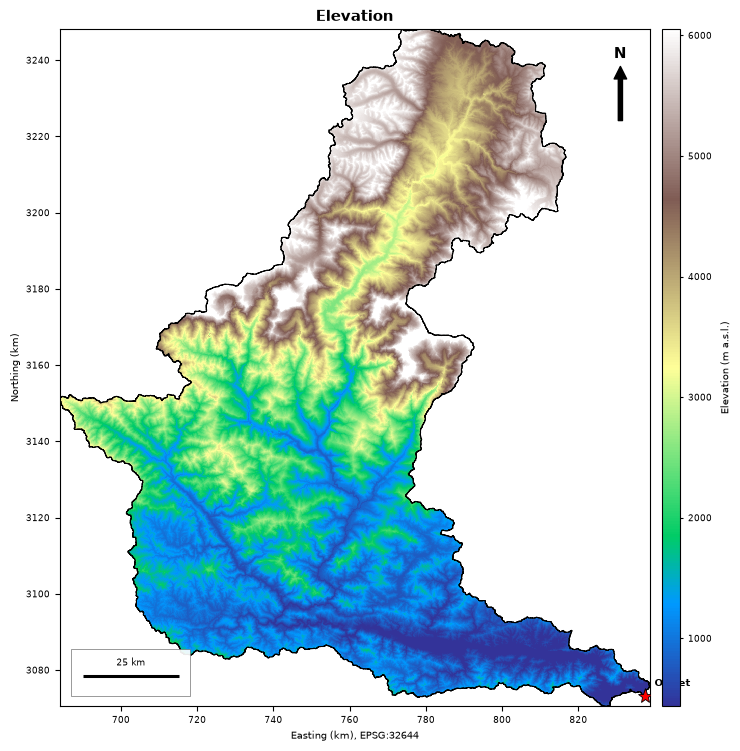

WindowsPath('D:/Watershed_Analysis/Outputs/Figures/02_dem.png')

In [7]:
# ============================================================
# 02_Terrain.ipynb | Cell 1: setup, clip DEM to watershed, elevation map
# ============================================================
import importlib
import numpy as np
from whitebox import WhiteboxTools
import utils
importlib.reload(utils)          # picks up edits to utils.py without restarting the kernel
from utils import *

P = get_paths()
DEM_CROP = P.RAS / "dem_cropped.tif"      # terrain derivatives come from this, not the conditioned DEM
TMP = P.RAS / "_tmp"                      # scratch space for full-size whitebox outputs
TMP.mkdir(exist_ok=True)

wbt = WhiteboxTools()
wbt.set_working_dir(str(TMP))
wbt.set_verbose_mode(False)

ws = WatershedGrid(P.RAS / "watershed_mask.tif",
                   P.VEC / "watershed_boundary.gpkg",
                   P.VEC / "outlet_snapped.shp")
print(ws)

# ---------- elevation, clipped ----------
dem = ws.read(DEM_CROP)
print(f"Elevation: min {np.nanmin(dem):,.0f} | mean {np.nanmean(dem):,.0f} | max {np.nanmax(dem):,.0f} m")
print(f"Valid cells in clip: {np.isfinite(dem).sum():,} (should equal {ws.n_cells:,})")

ws.save(dem, P.RAS / "dem.tif")
make_map(dem, ws, P.FIG / "02_dem.png",
         title="Elevation", label="Elevation (m a.s.l.)", cmap="terrain")

Slope (degrees)                rc=0     4.5 s
Aspect                         rc=0     4.5 s
Slope : min 0.0 | mean 28.1 | max 83.7 deg
Valid cells  slope: 13,631,535 | aspect: 13,631,535 (basin: 13,631,535)


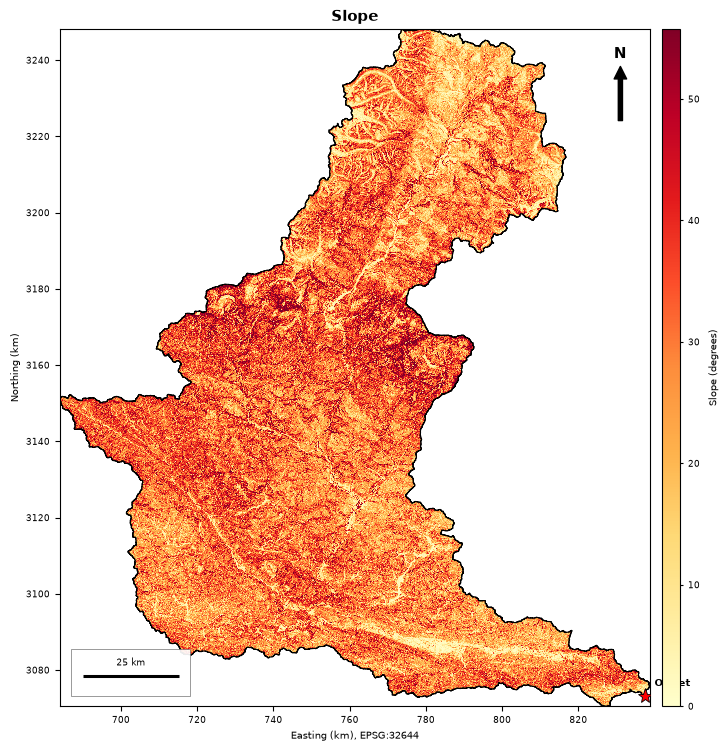

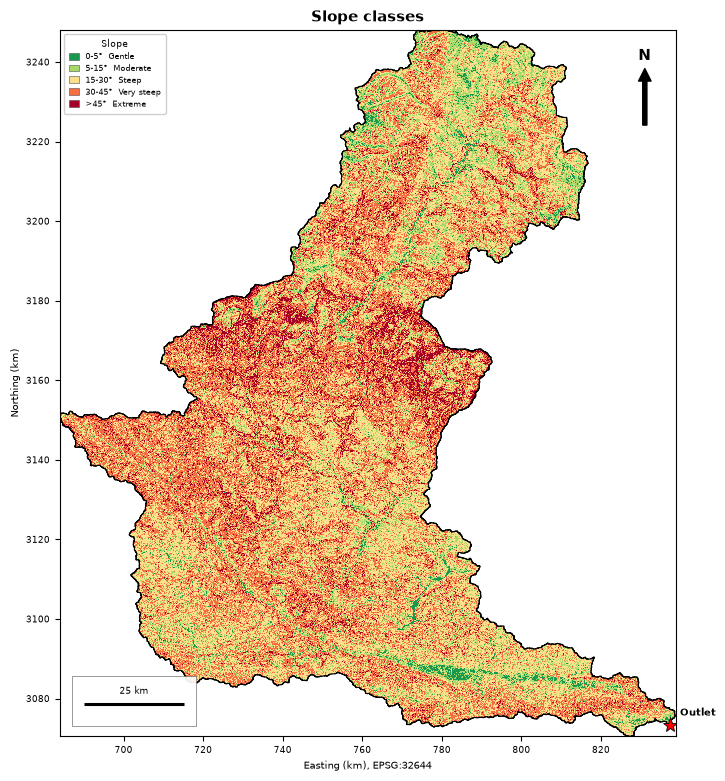

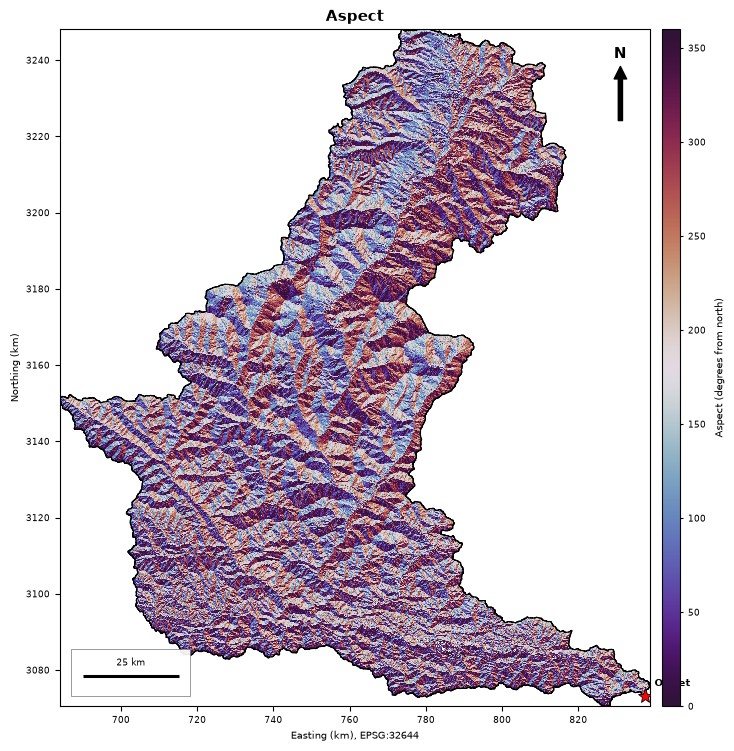

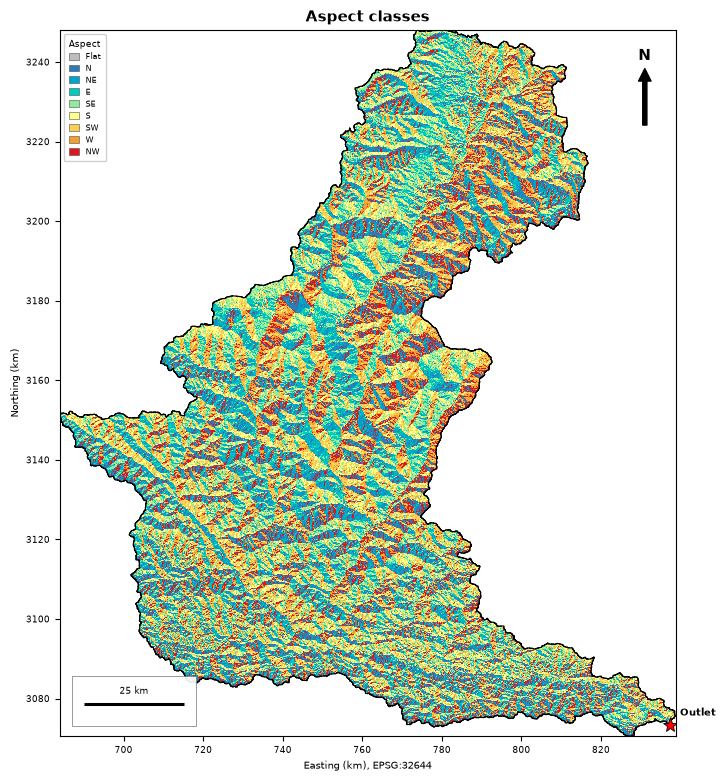

,class_id,label,cells,area_km2,percent
0,1,0-5° Gentle,370865,323.02,2.72
1,2,5-15° Moderate,1836924,1599.96,13.48
2,3,15-30° Steep,5465146,4760.15,40.09
3,4,30-45° Very steep,4654979,4054.49,34.15
4,5,>45° Extreme,1303621,1135.46,9.56


,class_id,label,cells,area_km2,percent
0,1,Flat,21691,18.89,0.16
1,2,N,1752293,1526.25,12.85
2,3,NE,1714837,1493.63,12.58
3,4,E,1646445,1434.06,12.08
4,5,SE,1763090,1535.65,12.93
5,6,S,1852923,1613.90,13.59
6,7,SW,1835261,1598.52,13.46
7,8,W,1522495,1326.10,11.17
8,9,NW,1522500,1326.10,11.17


,statistic,slope_deg
0,min,0.000000
1,mean,28.150000
2,median,27.940001
3,std,12.730000
4,p95,49.810001
5,max,83.680000


slope class polygons : 5 features  (5 s)
aspect class polygons: 9 features  (6 s)


In [8]:
# ============================================================
# Cell 2: slope + aspect (rasters, classes, maps, vectors, tables)
# ============================================================

# ---------- parameters ----------
SLOPE_BREAKS = [5, 15, 30, 45]                 # degrees -> 5 classes
SLOPE_LABELS = ["0-5°  Gentle", "5-15°  Moderate", "15-30°  Steep",
                "30-45°  Very steep", ">45°  Extreme"]
SLOPE_COLORS = ["#1a9850", "#a6d96a", "#fee08b", "#f46d43", "#a50026"]

FLAT_SLOPE_DEG = 1.0                           # cells flatter than this get aspect class "Flat"
ASPECT_LABELS = ["Flat", "N", "NE", "E", "SE", "S", "SW", "W", "NW"]
ASPECT_COLORS = ["#bdbdbd", "#2c7bb6", "#00a6ca", "#00ccbc", "#90eb9d",
                 "#ffff8c", "#f9d057", "#f29e2e", "#d7191c"]

# ---------- 1) whitebox on the full cropped DEM ----------
SLOPE_TMP  = TMP / "slope_full.tif"
ASPECT_TMP = TMP / "aspect_full.tif"

wbt_run("Slope (degrees)", wbt.slope, str(DEM_CROP), str(SLOPE_TMP), units="degrees")
wbt_run("Aspect",          wbt.aspect, str(DEM_CROP), str(ASPECT_TMP))

# ---------- 2) clip to the watershed ----------
slope  = ws.read(SLOPE_TMP)
aspect = ws.read(ASPECT_TMP)
aspect[aspect < 0] = -1            # whitebox marks flat cells as -1 in some versions
print(f"Slope : min {np.nanmin(slope):.1f} | mean {np.nanmean(slope):.1f} | "
      f"max {np.nanmax(slope):.1f} deg")
print(f"Valid cells  slope: {np.isfinite(slope).sum():,} | aspect: {np.isfinite(aspect).sum():,} "
      f"(basin: {ws.n_cells:,})")

# ---------- 3) classes ----------
slope_cls = classify(slope, SLOPE_BREAKS)

asp_cls = np.full(aspect.shape, np.nan, dtype="float32")
ok = np.isfinite(aspect)
sector = np.floor(((aspect[ok] + 22.5) % 360) / 45).astype("int8")   # 0=N ... 7=NW
asp_cls[ok] = sector + 2                                              # 2..9
flat = ok & ((aspect < 0) | (np.nan_to_num(slope) < FLAT_SLOPE_DEG))
asp_cls[flat] = 1                                                     # Flat
aspect_plot = np.where(flat, np.nan, aspect)                          # continuous map excludes flat

# ---------- 4) save rasters ----------
ws.save(slope,     P.RAS / "slope_deg.tif")
ws.save(aspect,    P.RAS / "aspect_deg.tif")
ws.save(slope_cls, P.RAS / "slope_classes.tif", nodata=0, dtype="uint8")
ws.save(asp_cls,   P.RAS / "aspect_classes.tif", nodata=0, dtype="uint8")

# ---------- 5) maps ----------
make_map(slope, ws, P.FIG / "02_slope.png", title="Slope",
         label="Slope (degrees)", cmap="YlOrRd", vmin=0)

make_map(slope_cls, ws, P.FIG / "02_slope_classes.png", title="Slope classes",
         label="Slope", classes=[(i + 1, SLOPE_LABELS[i], SLOPE_COLORS[i])
                                 for i in range(len(SLOPE_LABELS))])

make_map(aspect_plot, ws, P.FIG / "02_aspect.png", title="Aspect",
         label="Aspect (degrees from north)", cmap="twilight_shifted", vmin=0, vmax=360)

make_map(asp_cls, ws, P.FIG / "02_aspect_classes.png", title="Aspect classes",
         label="Aspect", classes=[(i + 1, ASPECT_LABELS[i], ASPECT_COLORS[i])
                                  for i in range(len(ASPECT_LABELS))])

# ---------- 6) tables ----------
tab_slope  = class_table(slope_cls, SLOPE_LABELS, ws)
tab_aspect = class_table(asp_cls, ASPECT_LABELS, ws)
save_table(tab_slope,  P.TAB / "02_slope_classes.csv")
save_table(tab_aspect, P.TAB / "02_aspect_classes.csv")

s = slope[np.isfinite(slope)]
slope_stats = pd.DataFrame({"statistic": ["min", "mean", "median", "std", "p95", "max"],
                            "slope_deg": [s.min(), s.mean(), np.median(s), s.std(),
                                          np.percentile(s, 95), s.max()]}).round(2)
save_table(slope_stats, P.TAB / "02_slope_statistics.csv")
display(tab_slope); display(tab_aspect); display(slope_stats)

# ---------- 7) vectors (class polygons) ----------
# This can take a few minutes on a basin this size; sieve_px merges specks smaller than that many cells.
t0 = time.time()
g_slope = classes_to_vector(slope_cls, ws, SLOPE_LABELS, P.VEC / "slope_classes", sieve_px=50)
print(f"slope class polygons : {len(g_slope)} features  ({time.time()-t0:.0f} s)")
t0 = time.time()
g_asp = classes_to_vector(asp_cls, ws, ASPECT_LABELS, P.VEC / "aspect_classes", sieve_px=100)
print(f"aspect class polygons: {len(g_asp)} features  ({time.time()-t0:.0f} s)")

TPI windows: 11x11 = 0.32 km | 35x35 = 1.03 km
Hillshade                      rc=0     4.7 s
TPI small                      rc=0     5.4 s
TPI large                      rc=0     5.4 s
Profile curvature              rc=0     4.5 s
Plan curvature                 rc=0     8.2 s
Total curvature                rc=0     7.8 s
TRI (Riley, 3x3)               rc=0     6.5 s
Profile curvature : sign already + convex / - concave
Plan curvature    : sign already + convex / - concave
Total curvature   : sign already + convex / - concave


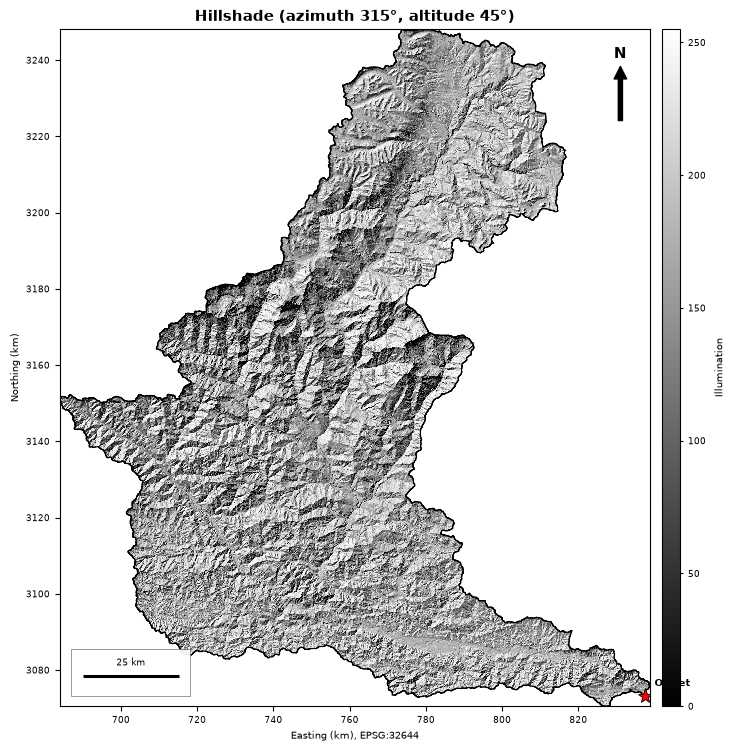

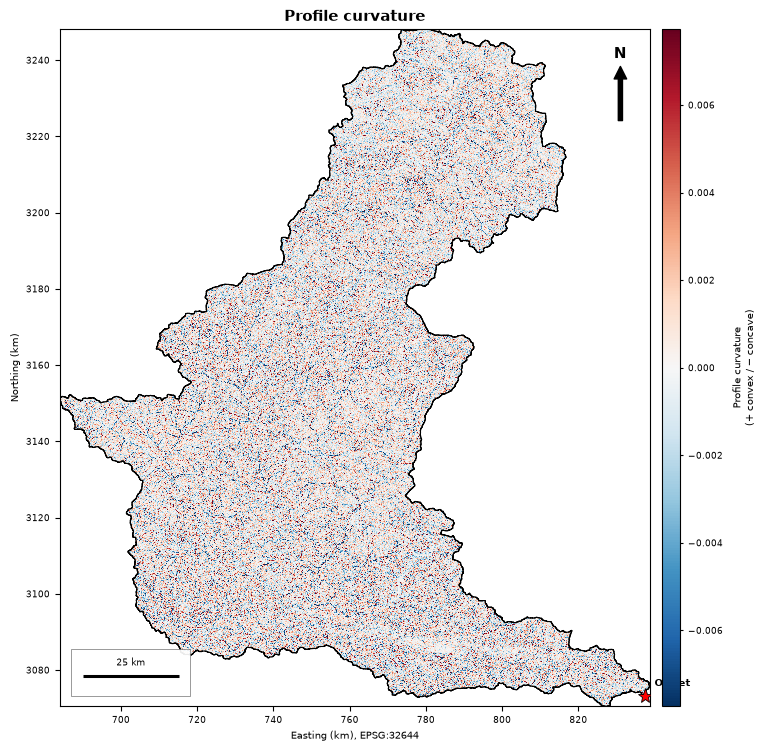

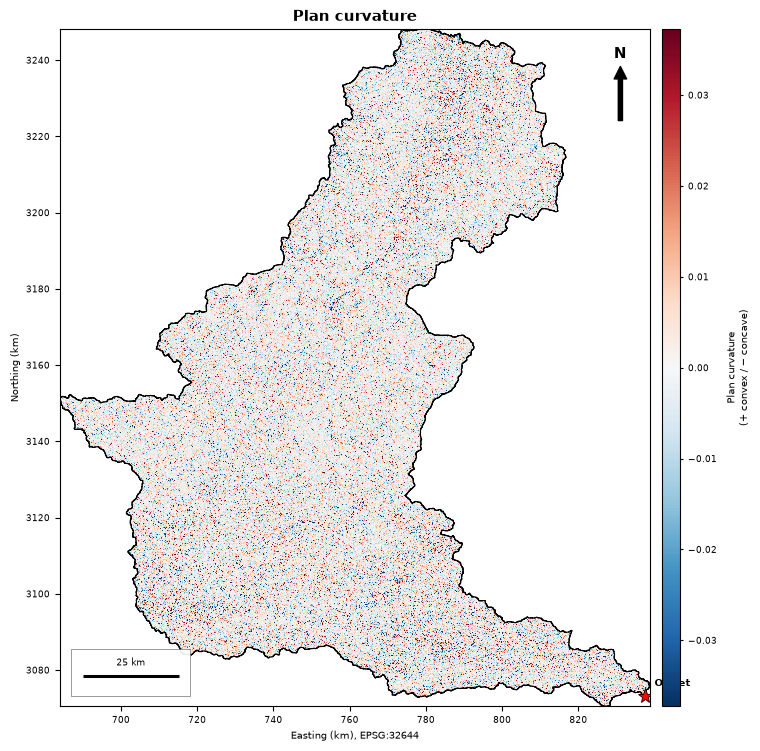

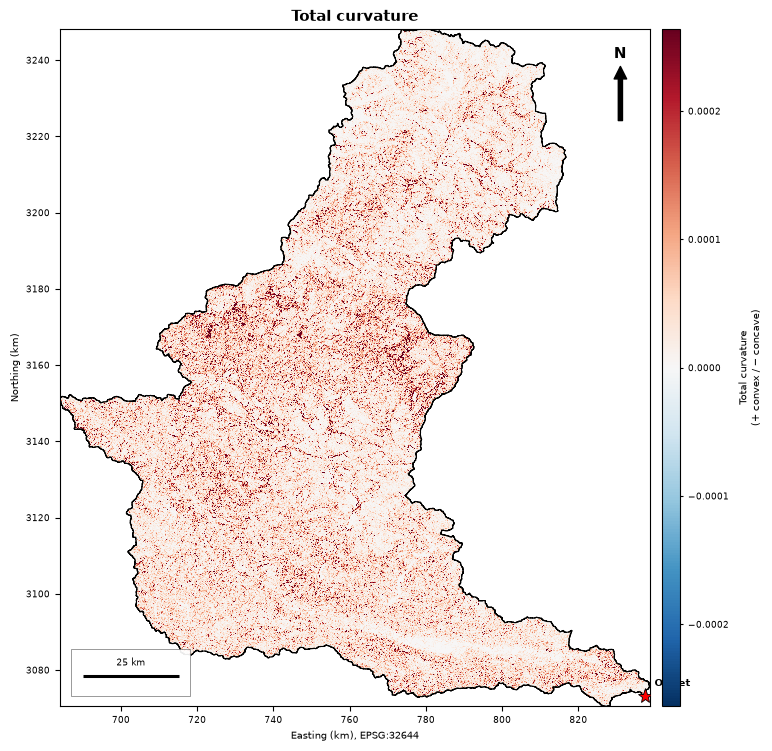

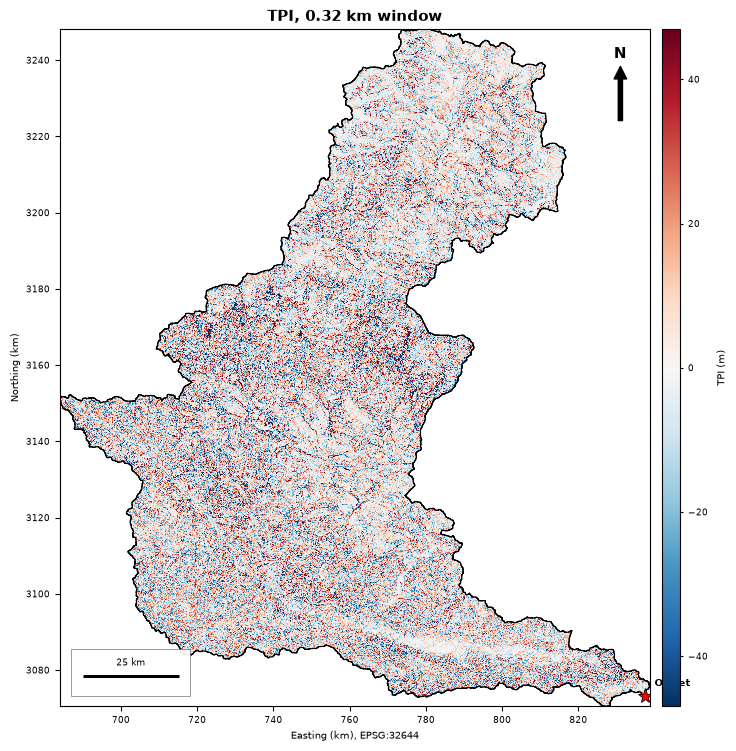

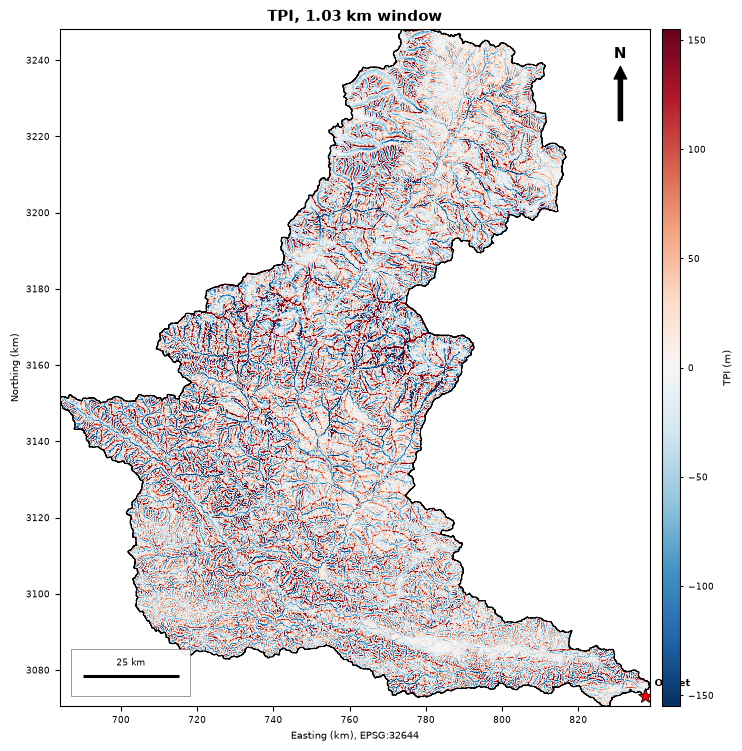

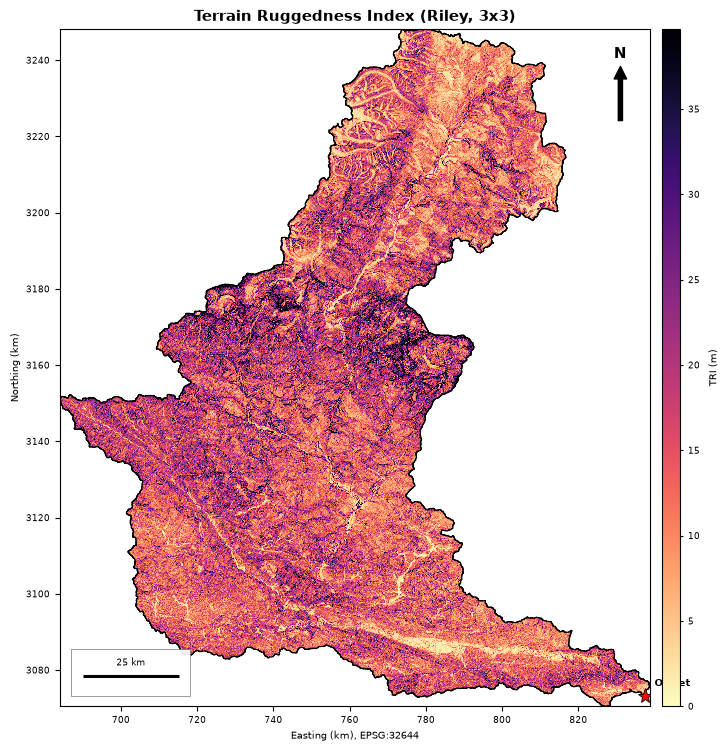

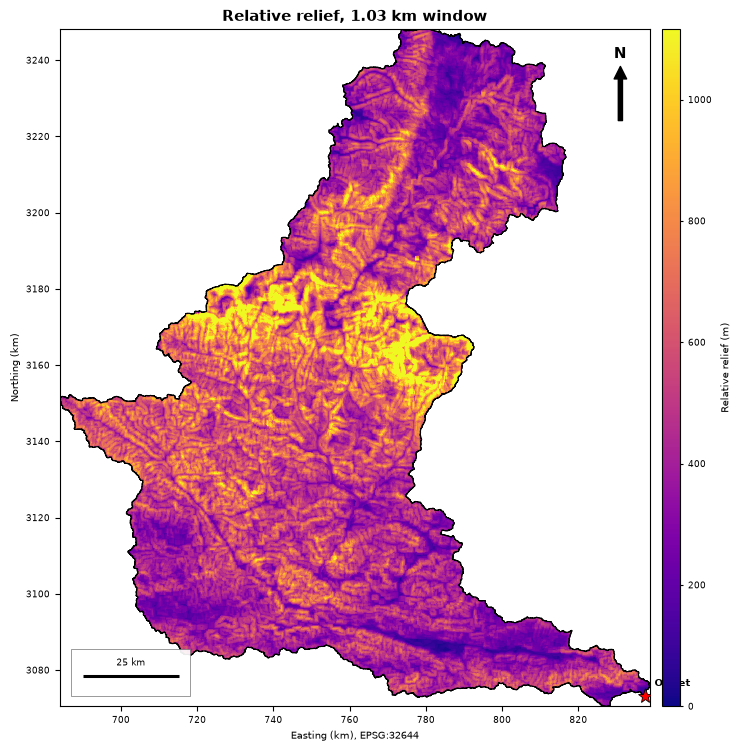

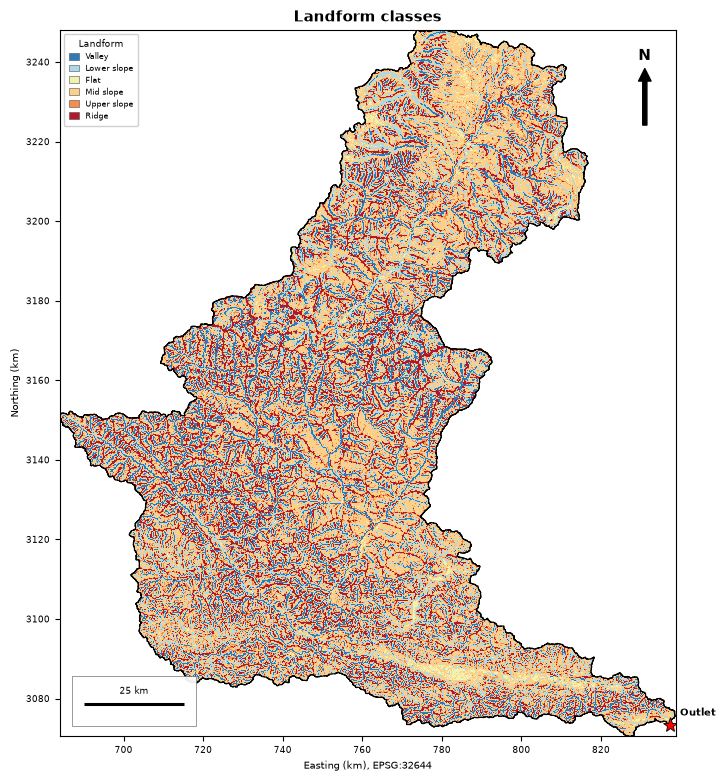

,layer,min,p2,mean,median,std,p98,max
0,tpi_small_m,-444.297485,-39.578499,0.001300,-0.4050,18.807800,40.719002,615.099182
1,tpi_large_m,-492.418793,-129.489807,-0.001500,-2.7976,64.720497,140.696304,696.211426
2,curv_profile,-0.063100,-0.006300,-0.000100,-0.0001,0.002700,0.006000,0.089500
3,curv_plan,-11.088700,-0.026100,-0.000000,0.0001,0.020300,0.025100,12.805600
4,curv_total,0.000000,0.000000,0.000000,0.0000,0.000100,0.000300,0.090200
5,tri_m,0.000000,2.715700,15.773100,14.3832,9.002100,39.673698,536.966187
6,relief_m,16.000000,173.000000,536.018677,505.0000,227.282700,1116.000000,2125.000000


,class_id,label,cells,area_km2,percent
0,1,Valley,1999776,1741.81,14.67
1,2,Lower slope,2154092,1876.22,15.80
2,3,Flat,194865,169.73,1.43
3,4,Mid slope,5380708,4686.61,39.47
4,5,Upper slope,1793310,1561.98,13.16
5,6,Ridge,2108784,1836.75,15.47


landform polygons: 6 features  (7 s)


In [9]:
# ============================================================
# Cell 3: hillshade, TPI (2 scales), curvature, TRI, relative relief, landforms
# ============================================================
from scipy import ndimage

# ---------- parameters ----------
TPI_SMALL, TPI_LARGE, RELIEF_WIN = 11, 35, 35          # window sizes in cells
km_small = TPI_SMALL * ws.res[0] / 1000
km_large = TPI_LARGE * ws.res[0] / 1000
print(f"TPI windows: {TPI_SMALL}x{TPI_SMALL} = {km_small:.2f} km | "
      f"{TPI_LARGE}x{TPI_LARGE} = {km_large:.2f} km")

LF_LABELS = ["Valley", "Lower slope", "Flat", "Mid slope", "Upper slope", "Ridge"]
LF_COLORS = ["#2c7bb6", "#abd9e9", "#f2f2b0", "#fdd08a", "#f28e4f", "#b2182b"]

# ---------- 1) whitebox on the full cropped DEM ----------
f = {n: TMP / f"{n}_full.tif" for n in
     ["hillshade", "tpi_small", "tpi_large", "profc", "planc", "totc", "tri"]}
D = str(DEM_CROP)

wbt_run("Hillshade",        wbt.hillshade, D, str(f["hillshade"]), azimuth=315.0, altitude=45.0)
wbt_run("TPI small",        wbt.diff_from_mean_elev, D, str(f["tpi_small"]), filterx=TPI_SMALL, filtery=TPI_SMALL)
wbt_run("TPI large",        wbt.diff_from_mean_elev, D, str(f["tpi_large"]), filterx=TPI_LARGE, filtery=TPI_LARGE)
wbt_run("Profile curvature", wbt.profile_curvature, D, str(f["profc"]))
wbt_run("Plan curvature",    wbt.plan_curvature, D, str(f["planc"]))
wbt_run("Total curvature",   wbt.total_curvature, D, str(f["totc"]))
wbt_run("TRI (Riley, 3x3)",  wbt.ruggedness_index, D, str(f["tri"]))

# ---------- 2) clip to the watershed ----------
hs      = ws.read(f["hillshade"]);  hs = hs / np.nanmax(hs) * 255
tpi_s   = ws.read(f["tpi_small"])
tpi_l   = ws.read(f["tpi_large"])
profc   = ws.read(f["profc"])
planc   = ws.read(f["planc"])
totc    = ws.read(f["totc"])
tri     = ws.read(f["tri"])
slope_c = ws.read(TMP / "slope_full.tif")               # from Cell 2

# ---------- 3) make curvature sign consistent: + convex (ridge), - concave (valley) ----------
def orient(c, name):
    hi = tpi_s > np.nanpercentile(tpi_s, 90)             # ridges / convex spots
    lo = tpi_s < np.nanpercentile(tpi_s, 10)             # valleys / concave spots
    d = np.nanmedian(c[hi]) - np.nanmedian(c[lo])
    if d < 0:
        print(f"{name:<18}: sign flipped (tool convention was opposite)")
        return -c
    print(f"{name:<18}: sign already + convex / - concave")
    return c

profc = orient(profc, "Profile curvature")
planc = orient(planc, "Plan curvature")
totc  = orient(totc,  "Total curvature")

# ---------- 4) relative relief (max - min in a window), on the full DEM ----------
with rasterio.open(DEM_CROP) as src:
    full = src.read(1).astype("float32")
r0, c0 = int(ws.window.row_off), int(ws.window.col_off)
r1, c1 = r0 + int(ws.window.height), c0 + int(ws.window.width)
mx = ndimage.maximum_filter(full, size=RELIEF_WIN, mode="nearest")
mn = ndimage.minimum_filter(full, size=RELIEF_WIN, mode="nearest")
relief = (mx - mn)[r0:r1, c0:c1].astype("float32")
del full, mx, mn
relief[~ws.mask] = np.nan

# ---------- 5) landform classes from large TPI (standardised) + slope ----------
z = tpi_l / np.nanstd(tpi_l)
ok = np.isfinite(z) & np.isfinite(slope_c)
flatish = np.abs(z) < 0.5
conds = [z <= -1,
         (z > -1) & (z <= -0.5),
         flatish & (slope_c <= 5),
         flatish & (slope_c > 5),
         (z >= 0.5) & (z < 1),
         z >= 1]
lf = np.select(conds, [1, 2, 3, 4, 5, 6], default=0).astype("float32")
lf[~ok] = np.nan
lf[lf == 0] = np.nan

# ---------- 6) save rasters ----------
ws.save(hs,     P.RAS / "hillshade.tif")
ws.save(tpi_s,  P.RAS / "tpi_small.tif")
ws.save(tpi_l,  P.RAS / "tpi_large.tif")
ws.save(profc,  P.RAS / "curvature_profile.tif")
ws.save(planc,  P.RAS / "curvature_plan.tif")
ws.save(totc,   P.RAS / "curvature_total.tif")
ws.save(tri,    P.RAS / "tri.tif")
ws.save(relief, P.RAS / "relative_relief.tif")
ws.save(lf,     P.RAS / "landform_classes.tif", nodata=0, dtype="uint8")

# ---------- 7) maps ----------
make_map(hs, ws, P.FIG / "02_hillshade.png", title="Hillshade (azimuth 315°, altitude 45°)",
         label="Illumination", cmap="gray", vmin=0, vmax=255)

for arr, stem, ttl, lab in [
        (profc, "02_curvature_profile", "Profile curvature", "Profile curvature\n(+ convex / − concave)"),
        (planc, "02_curvature_plan",    "Plan curvature",    "Plan curvature\n(+ convex / − concave)"),
        (totc,  "02_curvature_total",   "Total curvature",   "Total curvature\n(+ convex / − concave)")]:
    lo_, hi_ = sym_limits(arr)
    make_map(arr, ws, P.FIG / f"{stem}.png", title=ttl, label=lab,
             cmap="RdBu_r", vmin=lo_, vmax=hi_)

lo_, hi_ = sym_limits(tpi_s)
make_map(tpi_s, ws, P.FIG / "02_tpi_small.png", title=f"TPI, {km_small:.2f} km window",
         label="TPI (m)", cmap="RdBu_r", vmin=lo_, vmax=hi_)
lo_, hi_ = sym_limits(tpi_l)
make_map(tpi_l, ws, P.FIG / "02_tpi_large.png", title=f"TPI, {km_large:.2f} km window",
         label="TPI (m)", cmap="RdBu_r", vmin=lo_, vmax=hi_)

make_map(tri, ws, P.FIG / "02_tri.png", title="Terrain Ruggedness Index (Riley, 3x3)",
         label="TRI (m)", cmap="magma_r", vmin=0)
make_map(relief, ws, P.FIG / "02_relative_relief.png",
         title=f"Relative relief, {km_large:.2f} km window",
         label="Relative relief (m)", cmap="plasma", vmin=0)

make_map(lf, ws, P.FIG / "02_landforms.png", title="Landform classes",
         label="Landform", classes=[(i + 1, LF_LABELS[i], LF_COLORS[i]) for i in range(6)])

# ---------- 8) tables ----------
layers = {"tpi_small_m": tpi_s, "tpi_large_m": tpi_l, "curv_profile": profc,
          "curv_plan": planc, "curv_total": totc, "tri_m": tri, "relief_m": relief}
rows = []
for name, a in layers.items():
    v = a[np.isfinite(a)]
    rows.append(dict(layer=name, min=v.min(), p2=np.percentile(v, 2), mean=v.mean(),
                     median=np.median(v), std=v.std(), p98=np.percentile(v, 98), max=v.max()))
terrain_stats = pd.DataFrame(rows).round(4)
save_table(terrain_stats, P.TAB / "02_terrain_statistics.csv")

tab_lf = class_table(lf, LF_LABELS, ws)
save_table(tab_lf, P.TAB / "02_landform_classes.csv")
display(terrain_stats); display(tab_lf)

# ---------- 9) vectors ----------
t0 = time.time()
g_lf = classes_to_vector(lf, ws, LF_LABELS, P.VEC / "landform_classes", sieve_px=100)
print(f"landform polygons: {len(g_lf)} features  ({time.time() - t0:.0f} s)")

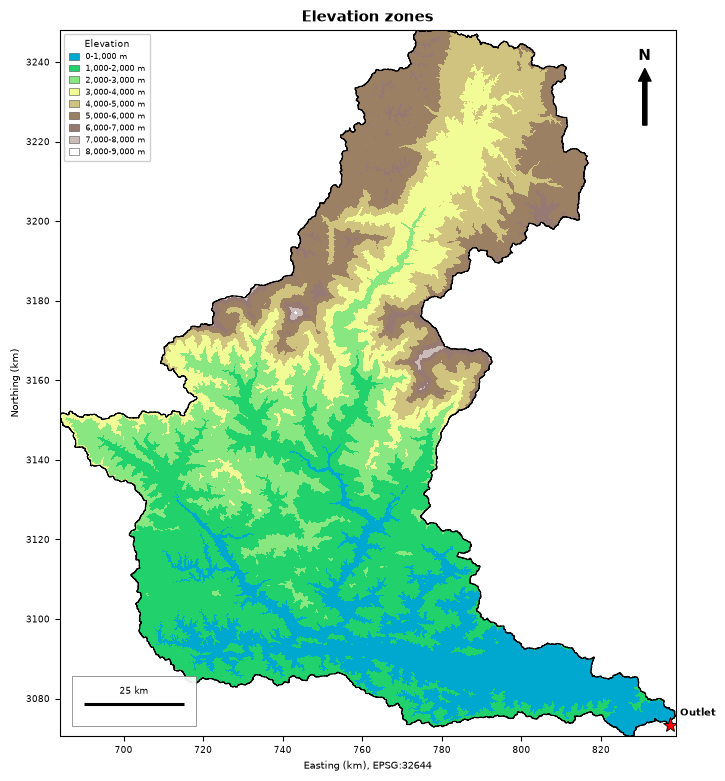

,class_id,label,cells,area_km2,percent
0,1,"0-1,000 m",2193471,1910.52,16.09
1,2,"1,000-2,000 m",3862214,3363.99,28.33
2,3,"2,000-3,000 m",1983274,1727.43,14.55
3,4,"3,000-4,000 m",1603707,1396.83,11.76
4,5,"4,000-5,000 m",1707952,1487.63,12.53
5,6,"5,000-6,000 m",1947051,1695.88,14.28
6,7,"6,000-7,000 m",304577,265.29,2.23
7,8,"7,000-8,000 m",28908,25.18,0.21
8,9,"8,000-9,000 m",381,0.33,0.00


elevation zone polygons: 9 features (5 s)
contours: 3,653 lines, 821 index lines (18 s)


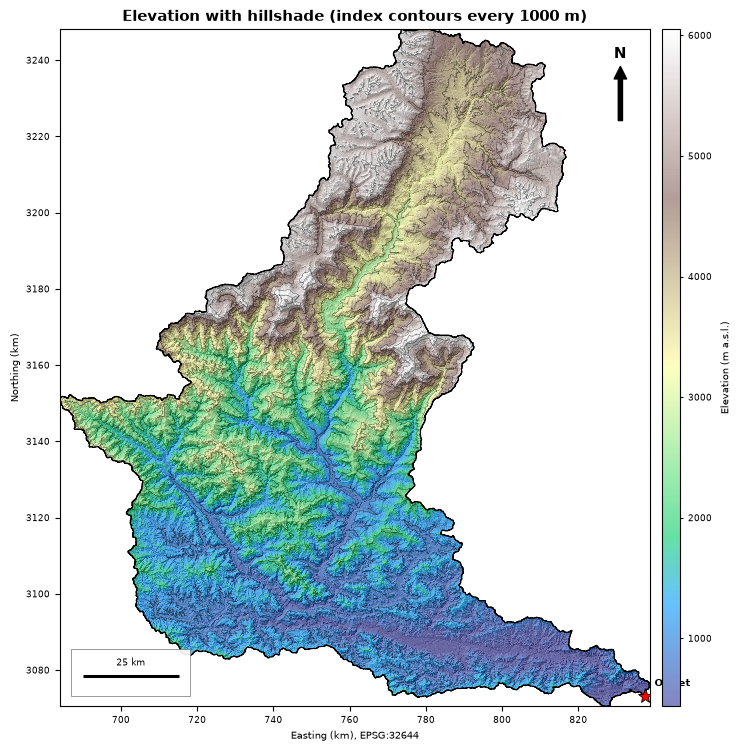

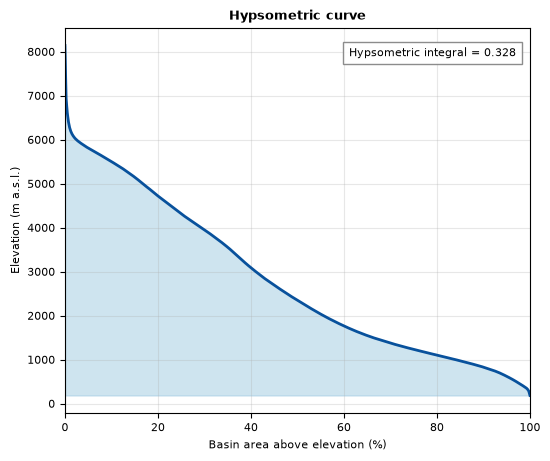

,statistic,value
0,min_m,184.000
1,max_m,8141.000
2,mean_m,2797.275
3,median_m,2345.000
4,std_m,1762.240
5,basin_relief_m,7957.000
6,hypsometric_integral,0.328
7,area_km2,11873.089



file                                    MB
aspect_classes.tif                     3.2
aspect_deg.tif                        62.5
breach_difference_m.tif                1.4
curvature_plan.tif                    68.6
curvature_profile.tif                 68.2
curvature_total.tif                   65.6
d8_direction_classes.tif               3.8
d8_direction_codes.tif                 3.8
dem.tif                               26.7
dem_conditioned.tif                  674.5
dem_cropped.tif                      139.5
elevation_zones.tif                    0.5
flow_accumulation.tif                337.3
flow_accumulation_km2.tif             17.3
flow_direction.tif                   168.7
flow_length_downstream_m.tif          42.8
flow_length_upstream_max_m.tif        21.4
hillshade.tif                         59.5
landform_classes.tif                   2.0
relative_relief.tif                   23.1
sca_dinf_m.tif                        58.3
slope_classes.tif                      2.6
slope_deg.

In [10]:
# ============================================================
# Cell 4: elevation zones, contours, hypsometric curve, output inventory
# ============================================================

# ---------- parameters ----------
ZONE_STEP        = 1000      # m, elevation zone width
CONTOUR_INTERVAL = 200       # m
INDEX_EVERY      = 5         # every 5th contour is an index contour (1000 m)

# ---------- 1) elevation zones ----------
zmin = np.floor(np.nanmin(dem) / ZONE_STEP) * ZONE_STEP
zmax = np.ceil(np.nanmax(dem) / ZONE_STEP) * ZONE_STEP
z_breaks = np.arange(zmin + ZONE_STEP, zmax, ZONE_STEP)
n_z = len(z_breaks) + 1
Z_LABELS = [f"{zmin + i*ZONE_STEP:,.0f}-{zmin + (i+1)*ZONE_STEP:,.0f} m" for i in range(n_z)]
Z_COLORS = [plt.get_cmap("terrain")(v) for v in np.linspace(0.18, 1.0, n_z)]
Z_COLORS = ["#%02x%02x%02x" % tuple(int(255 * c) for c in col[:3]) for col in Z_COLORS]

elev_cls = classify(dem, z_breaks)
ws.save(elev_cls, P.RAS / "elevation_zones.tif", nodata=0, dtype="uint8")

make_map(elev_cls, ws, P.FIG / "02_elevation_zones.png", title="Elevation zones",
         label="Elevation", classes=[(i + 1, Z_LABELS[i], Z_COLORS[i]) for i in range(n_z)])

tab_z = class_table(elev_cls, Z_LABELS, ws)
save_table(tab_z, P.TAB / "02_elevation_zones.csv")
display(tab_z)

t0 = time.time()
g_z = classes_to_vector(elev_cls, ws, Z_LABELS, P.VEC / "elevation_zones", sieve_px=100)
print(f"elevation zone polygons: {len(g_z)} features ({time.time() - t0:.0f} s)")

# ---------- 2) contours ----------
t0 = time.time()
g_c = contours_to_vector(dem, ws, CONTOUR_INTERVAL, P.VEC / "contours", index_every=INDEX_EVERY)
print(f"contours: {len(g_c):,} lines, {g_c['index'].sum():,} index lines ({time.time() - t0:.0f} s)")

# ---------- 3) DEM over hillshade with index contours ----------
make_map(dem, ws, P.FIG / "02_dem_hillshade.png",
         title=f"Elevation with hillshade (index contours every {CONTOUR_INTERVAL * INDEX_EVERY} m)",
         label="Elevation (m a.s.l.)", cmap="terrain", hillshade=hs,
         overlay=g_c[g_c["index"]], overlay_kw=dict(color="k", linewidth=0.3, alpha=0.7))

# ---------- 4) hypsometric curve + integral ----------
v = dem[np.isfinite(dem)]
pct = np.linspace(0, 100, 401)
elev_p = np.percentile(v, pct)
area_above = 100 - pct                                   # % of basin area above that elevation
hi_ = (v.mean() - v.min()) / (v.max() - v.min())         # hypsometric integral

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(area_above, elev_p, color="#08519c", lw=2)
ax.fill_between(area_above, elev_p, v.min(), color="#9ecae1", alpha=0.5)
ax.set_xlim(0, 100)
ax.set_xlabel("Basin area above elevation (%)")
ax.set_ylabel("Elevation (m a.s.l.)")
ax.set_title("Hypsometric curve", fontweight="bold")
ax.text(0.97, 0.95, f"Hypsometric integral = {hi_:.3f}", transform=ax.transAxes,
        ha="right", va="top", fontsize=8, bbox=dict(fc="white", ec="0.5", alpha=0.9))
ax.grid(alpha=0.3)
fig.savefig(P.FIG / "02_hypsometric_curve.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

hyps = pd.DataFrame({"area_above_pct": area_above.round(2), "elevation_m": elev_p.round(1)})
save_table(hyps, P.TAB / "02_hypsometric_curve.csv")

# ---------- 5) elevation statistics ----------
elev_stats = pd.DataFrame({
    "statistic": ["min_m", "max_m", "mean_m", "median_m", "std_m", "basin_relief_m",
                  "hypsometric_integral", "area_km2"],
    "value": [v.min(), v.max(), v.mean(), np.median(v), v.std(), v.max() - v.min(),
              hi_, ws.area_km2]}).round(3)
save_table(elev_stats, P.TAB / "02_elevation_statistics.csv")
display(elev_stats)

# ---------- 6) output inventory ----------
print(f"\n{'file':<34}{'MB':>8}")
for folder in (P.RAS, P.VEC, P.FIG, P.TAB):
    for p in sorted(folder.glob("*")):
        if p.is_file() and p.suffix in {".tif", ".gpkg", ".shp", ".png", ".csv"}:
            if folder is P.VEC and p.name.startswith(("watershed", "outlet")):
                continue
            print(f"{p.name:<34}{p.stat().st_size / 1e6:>8.1f}")

# ---------- 7) optional cleanup of the full-size temp rasters ----------
tmp_mb = sum(p.stat().st_size for p in TMP.glob("*") if p.is_file()) / 1e6
print(f"\n_tmp folder holds {tmp_mb:,.0f} MB of scratch rasters.")



Total curvature: min 0.000000 | p50 0.000023 | p98 0.000264 | max 0.090151  (should be all >= 0)


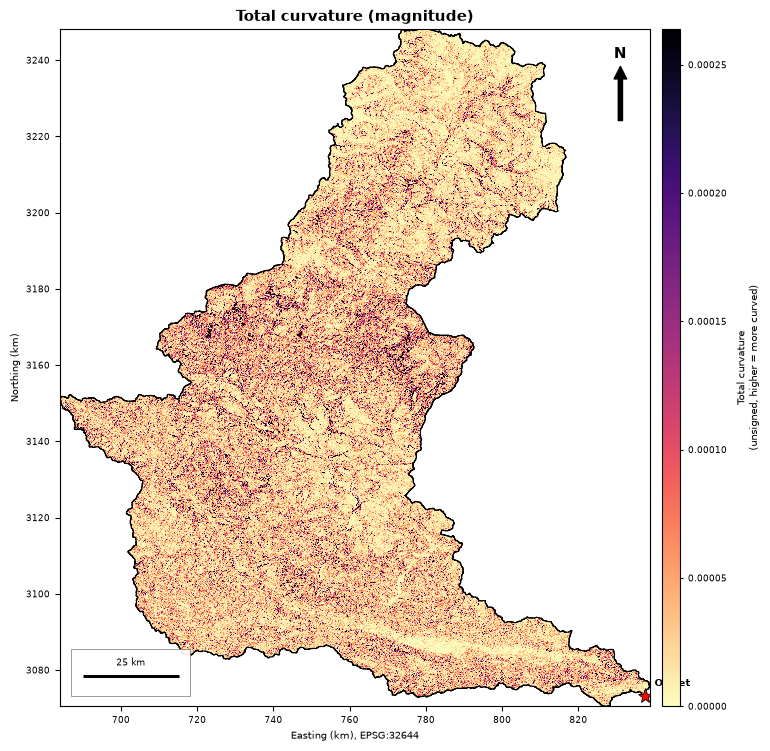

,layer,min,p2,mean,median,std,p98,max
0,tpi_small_m,-444.297516,-39.578514,0.001297,-0.404959,18.807781,40.719009,615.099182
1,tpi_large_m,-492.418762,-129.489792,-0.001480,-2.797551,64.720528,140.696320,696.211426
2,curv_profile,-0.063149,-0.006313,-0.000078,-0.000062,0.002732,0.006028,0.089521
3,curv_plan,-11.088687,-0.026105,-0.000016,0.000092,0.020325,0.025100,12.805642
4,curv_total,0.000000,0.000001,0.000048,0.000023,0.000101,0.000264,0.090151
5,tri_m,0.000000,2.715695,15.773120,14.383150,9.002125,39.673668,536.966248
6,relief_m,16.000000,173.000000,536.018677,505.000000,227.282730,1116.000000,2125.000000


In [11]:
# ============================================================
# Patch: total curvature (unsigned magnitude, no sign flip) + stats table
# ============================================================
totc = ws.read(f["totc"])
v = totc[np.isfinite(totc)]
print(f"Total curvature: min {v.min():.6f} | p50 {np.median(v):.6f} | "
      f"p98 {np.percentile(v, 98):.6f} | max {v.max():.6f}  (should be all >= 0)")

ws.save(totc, P.RAS / "curvature_total.tif")
make_map(totc, ws, P.FIG / "02_curvature_total.png", title="Total curvature (magnitude)",
         label="Total curvature\n(unsigned, higher = more curved)",
         cmap="magma_r", vmin=0, vmax=float(np.percentile(v, 98)))

layers["curv_total"] = totc
rows = []
for name, a in layers.items():
    x_ = a[np.isfinite(a)]
    rows.append(dict(layer=name, min=x_.min(), p2=np.percentile(x_, 2), mean=x_.mean(),
                     median=np.median(x_), std=x_.std(), p98=np.percentile(x_, 98), max=x_.max()))
terrain_stats = pd.DataFrame(rows).round(6)
save_table(terrain_stats, P.TAB / "02_terrain_statistics.csv")
display(terrain_stats)

The Next cell below, Shutil.rmtree , run this only after confirming everything above is okay. This removes space from _tmp

In [12]:
import shutil
shutil.rmtree(TMP, ignore_errors=True)
TMP.mkdir(exist_ok=True)      # keeps the working folder valid if you use whitebox again in this kernel
print("Scratch cleared.")

Scratch cleared.
